# From 4G to 6G: Network Performance & Business Impact
**Goal:** compare 4G, 5G NSA, 5G SA and simulated 6G across speed, latency, congestion, energy, revenue and satisfaction.

**Note:** the dataset is synthetic. The 6G rows are simulated from published research targets, and the use-case latency limits are my assumptions.

## 1. Load and inspect

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")

df = pd.read_csv("5G_6G_network_dataset.csv", parse_dates=["Date"])
order = ["4G LTE","5G NSA","5G SA","6G Testbed (Simulated)"]
df["Technology"] = pd.Categorical(df["Technology"], categories=order, ordered=True)
print(df.shape)
df.head()

(6000, 22)


,Date,City,Technology,Operator,Hour,Use_Case,Device_Type,Region,City_Tier,Band,...,Latency_ms,Jitter_ms,Packet_Loss_Pct,Signal_RSRP_dBm,Connected_Users,Energy_kWh_per_GB,Tower_ID,Monthly_Revenue_INR_per_User,Customer_Satisfaction_1to5,Is_Peak_Hour
0,2025-01-01,Delhi,4G LTE,Operator A,0,Telemedicine,Smartphone,North,Metro,B40 2300MHz,...,55.61,13.30,0.57,-99.0,822,0.0422,TWR0158,156.0,4.4,Off-Peak
1,2025-01-01,Siliguri,5G NSA,Operator B,18,Online Gaming,Smartphone,East,Tier-3,n28 700MHz,...,25.92,3.92,0.65,-102.0,409,0.0282,TWR0151,250.0,5.0,Peak
2,2025-01-01,Pune,5G NSA,Operator A,15,AR/VR,Smartphone,West,Tier-2,n28 700MHz,...,23.95,4.55,0.30,-102.0,863,0.0337,TWR0134,294.0,4.9,Off-Peak
3,2025-01-01,Siliguri,4G LTE,Operator C,16,AR/VR,Smartphone,East,Tier-3,B40 2300MHz,...,61.78,18.01,0.81,-98.0,794,0.0699,TWR0080,225.0,3.0,Off-Peak
4,2025-01-01,Siliguri,4G LTE,Operator A,17,Autonomous Vehicles,AR/VR Headset,East,Tier-3,B40 2300MHz,...,58.34,3.21,0.69,-93.0,991,0.0415,TWR0305,211.0,3.6,Off-Peak


In [7]:
print(df.isna().sum().sum(), "missing values;", df.duplicated().sum(), "duplicate rows")
df.describe().round(2)

0 missing values; 0 duplicate rows


,Date,Hour,Download_Mbps,Upload_Mbps,Latency_ms,Jitter_ms,Packet_Loss_Pct,Signal_RSRP_dBm,Connected_Users,Energy_kWh_per_GB,Monthly_Revenue_INR_per_User,Customer_Satisfaction_1to5
count,6000,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,2025-12-29 14:01:55.200000,11.57,363.89,84.90,25.82,4.52,0.63,-92.52,1184.78,0.04,327.78,4.55
min,2025-01-01 00:00:00,0.00,8.00,3.30,0.46,0.03,0.01,-128.00,53.00,0.01,109.00,2.20
25%,2025-07-03 00:00:00,5.00,54.98,15.68,10.40,1.59,0.29,-99.00,611.00,0.03,209.75,4.20
50%,2025-12-30 00:00:00,12.00,217.15,37.00,22.05,3.16,0.51,-93.00,1134.50,0.04,272.00,4.80
75%,2026-06-28 00:00:00,18.00,405.10,70.62,37.62,6.34,0.84,-85.00,1667.25,0.05,344.00,5.00
max,2026-12-31 00:00:00,23.00,4196.30,1098.70,113.42,33.69,4.69,-51.00,3198.00,0.12,1439.00,5.00
std,NaN,7.00,485.70,148.35,19.31,4.15,0.48,10.43,714.11,0.02,207.13,0.54


## 2. Generation comparison (KPIs)

In [8]:
kpi = df.groupby("Technology", observed=True).agg(
    avg_download=("Download_Mbps","mean"), avg_upload=("Upload_Mbps","mean"),
    avg_latency=("Latency_ms","mean"), packet_loss=("Packet_Loss_Pct","mean"),
    energy_kwh_gb=("Energy_kWh_per_GB","mean"), satisfaction=("Customer_Satisfaction_1to5","mean"),
    arpu_inr=("Monthly_Revenue_INR_per_User","mean")).round(2)
base = kpi.loc["4G LTE"]
kpi["speed_multiple_vs_4G"] = (kpi.avg_download / base.avg_download).round(1)
kpi["latency_reduction_%"] = ((1 - kpi.avg_latency / base.avg_latency) * 100).round(0)
kpi["energy_saving_%"] = ((1 - kpi.energy_kwh_gb / base.energy_kwh_gb) * 100).round(0)
kpi

,avg_download,avg_upload,avg_latency,packet_loss,energy_kwh_gb,satisfaction,arpu_inr,speed_multiple_vs_4G,latency_reduction_%,energy_saving_%
Technology,,,,,,,,,,
4G LTE,31.94,10.07,52.53,0.63,0.06,3.91,180.56,1.0,0.0,0.0
5G NSA,198.33,33.61,25.80,0.61,0.04,4.64,261.66,6.2,51.0,33.0
5G SA,429.85,74.58,10.59,0.64,0.03,4.88,346.52,13.5,80.0,50.0
6G Testbed (Simulated),1651.73,502.97,0.93,0.64,0.01,4.92,904.58,51.7,98.0,83.0


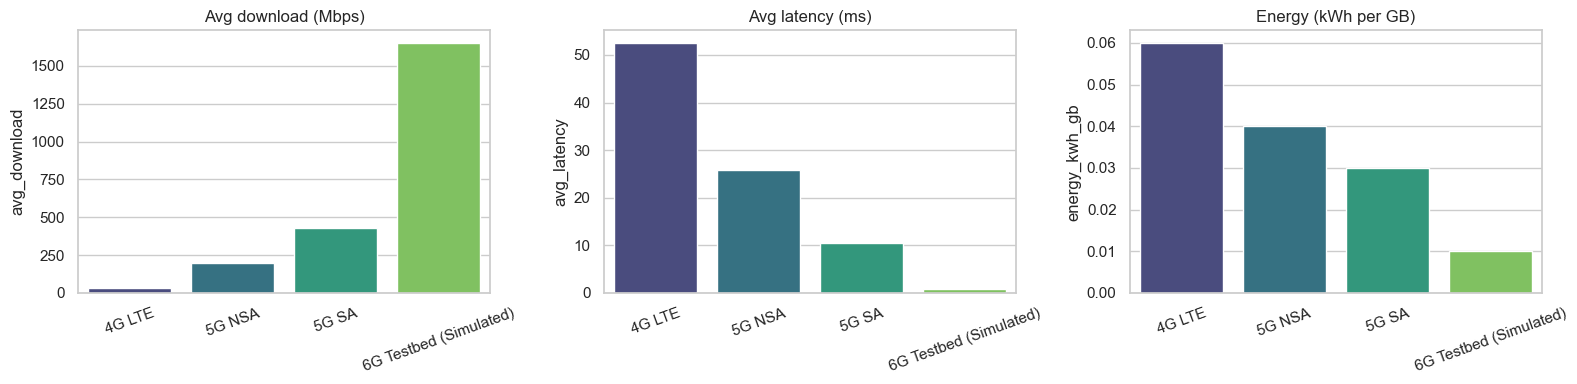

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, t in zip(ax, ["avg_download","avg_latency","energy_kwh_gb"],
                     ["Avg download (Mbps)","Avg latency (ms)","Energy (kWh per GB)"]):
    sns.barplot(x=kpi.index.astype(str), y=kpi[col], hue=kpi.index.astype(str), legend=False, ax=a, palette="viridis")
    a.set_title(t); a.set_xlabel(""); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 3. Digital divide: Metro vs Tier-2 vs Tier-3

Technology,4G LTE,5G NSA,5G SA,6G Testbed (Simulated),gap_vs_metro_5GSA_%
City_Tier,,,,,
Metro,36.1,221.9,490.5,1867.1,0.0
Tier-2,28.8,180.7,385.4,1479.6,21.0
Tier-3,21.9,139.3,296.8,1230.3,39.0


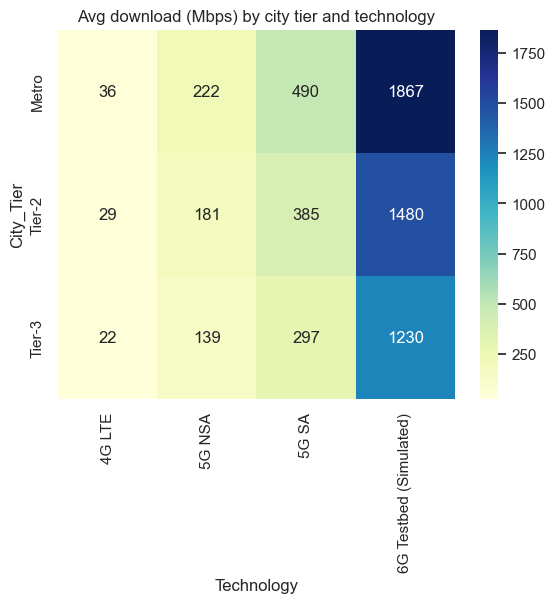

In [10]:
tier = df.pivot_table(index="City_Tier", columns="Technology", values="Download_Mbps",
                      aggfunc="mean", observed=True).round(1)
tier["gap_vs_metro_5GSA_%"] = ((1 - tier["5G SA"] / tier.loc["Metro","5G SA"]) * 100).round(0)
display(tier)
sns.heatmap(tier.drop(columns="gap_vs_metro_5GSA_%"), annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Avg download (Mbps) by city tier and technology"); plt.show()

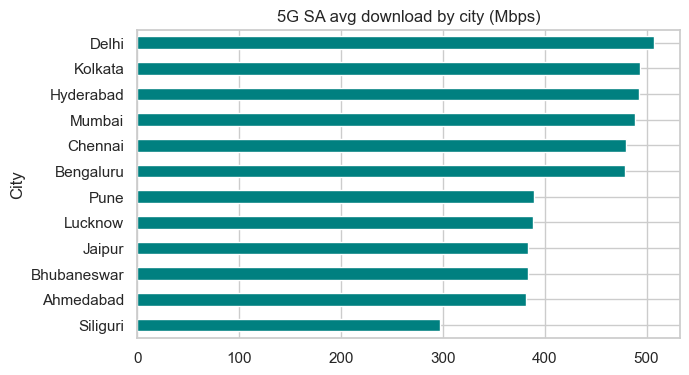

In [11]:
city = df[df.Technology=="5G SA"].groupby("City").Download_Mbps.mean().sort_values()
city.plot.barh(figsize=(7,4), color="teal", title="5G SA avg download by city (Mbps)"); plt.show()

## 4. Congestion: peak vs off-peak

Is_Peak_Hour,Off-Peak,Peak,drop_%
Technology,,,
4G LTE,34.8,23.8,32.0
5G NSA,215.3,148.3,31.0
5G SA,466.5,328.8,30.0
6G Testbed (Simulated),1768.6,1256.0,29.0


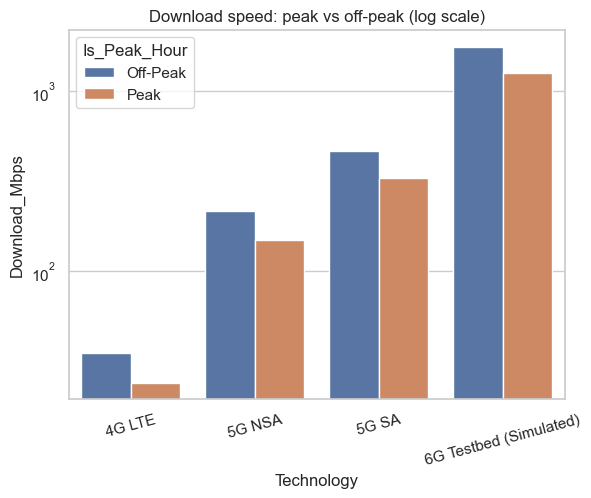

In [12]:
peak = df.pivot_table(index="Technology", columns="Is_Peak_Hour", values="Download_Mbps",
                      aggfunc="mean", observed=True).round(1)
peak["drop_%"] = ((1 - peak["Peak"] / peak["Off-Peak"]) * 100).round(0)
display(peak)
sns.barplot(data=df, x="Technology", y="Download_Mbps", hue="Is_Peak_Hour", errorbar=None)
plt.yscale("log"); plt.xticks(rotation=15); plt.title("Download speed: peak vs off-peak (log scale)"); plt.show()

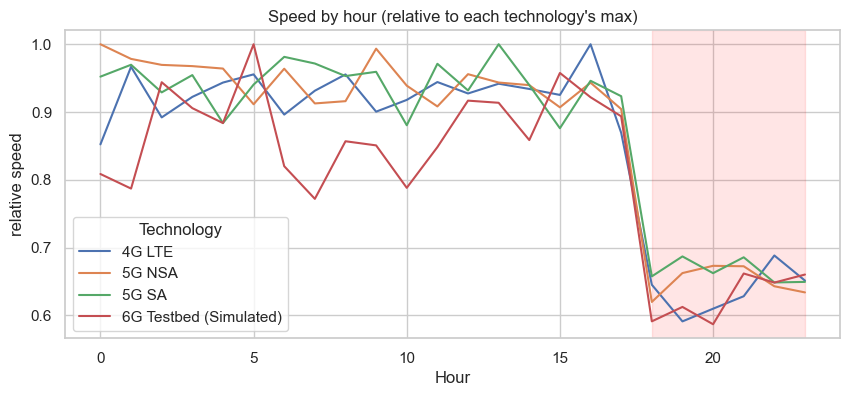

In [13]:
hourly = df.groupby(["Hour","Technology"], observed=True).Download_Mbps.mean().unstack()
(hourly / hourly.max()).plot(figsize=(10,4), title="Speed by hour (relative to each technology's max)")
plt.axvspan(18, 23, alpha=0.1, color="red"); plt.ylabel("relative speed"); plt.show()

## 5. Use-case fit (latency SLA)
The maximum latency per use case is an assumption.

Technology,max_latency_ms,4G LTE,5G NSA,5G SA,6G Testbed (Simulated)
Use_Case,,,,,
AR/VR,10,0.0,0.0,45.0,100.0
Autonomous Vehicles,5,0.0,0.0,0.0,100.0
Industrial IoT,10,0.0,0.0,41.0,100.0
Online Gaming,20,0.0,15.0,100.0,100.0
Remote Work,50,49.0,100.0,100.0,100.0
Smart City IoT,100,100.0,100.0,100.0,100.0
Telemedicine,10,0.0,0.0,47.0,100.0
Video Streaming,50,48.0,100.0,100.0,100.0


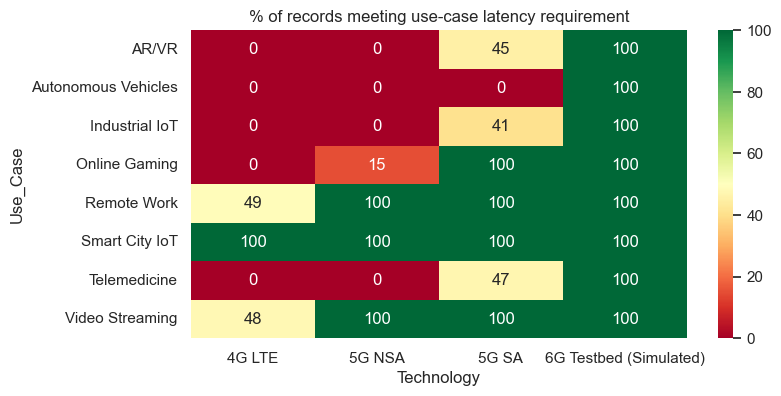

In [14]:
req = {"Video Streaming":50,"Online Gaming":20,"Smart City IoT":100,"Telemedicine":10,
       "Autonomous Vehicles":5,"Industrial IoT":10,"AR/VR":10,"Remote Work":50}
df["meets_sla"] = df.Latency_ms <= df.Use_Case.map(req)
sla = (df.pivot_table(index="Use_Case", columns="Technology", values="meets_sla",
                      aggfunc="mean", observed=True) * 100).round(0)
sla.insert(0, "max_latency_ms", pd.Series(req))
display(sla)
plt.figure(figsize=(8,4))
sns.heatmap(sla.drop(columns="max_latency_ms"), annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100)
plt.title("% of records meeting use-case latency requirement"); plt.show()

## 6. Business impact: what drives satisfaction?

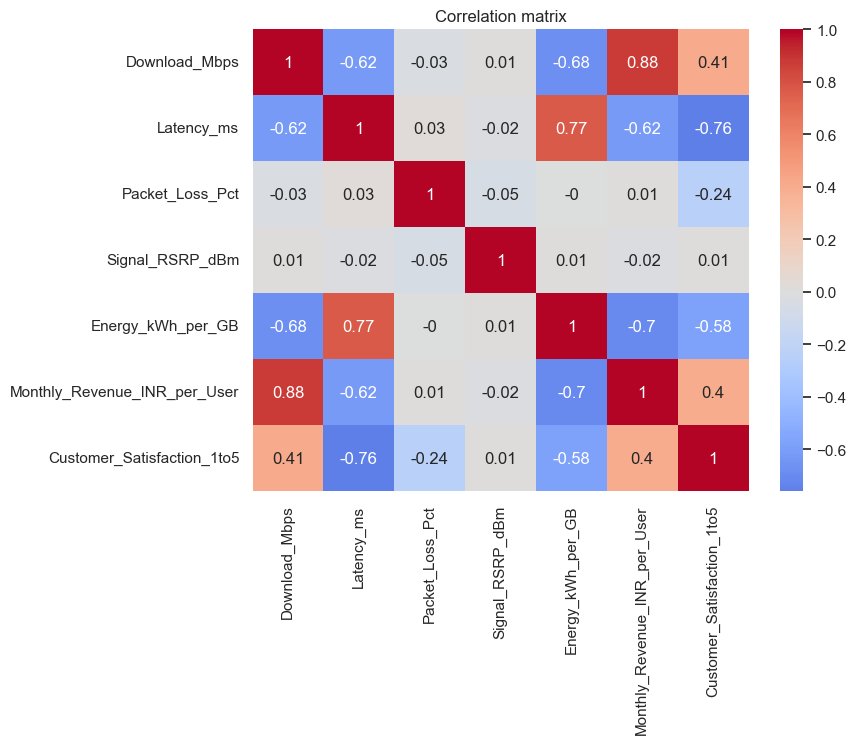

In [15]:
cols = ["Download_Mbps","Latency_ms","Packet_Loss_Pct","Signal_RSRP_dBm","Energy_kWh_per_GB",
        "Monthly_Revenue_INR_per_User","Customer_Satisfaction_1to5"]
plt.figure(figsize=(8,6))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

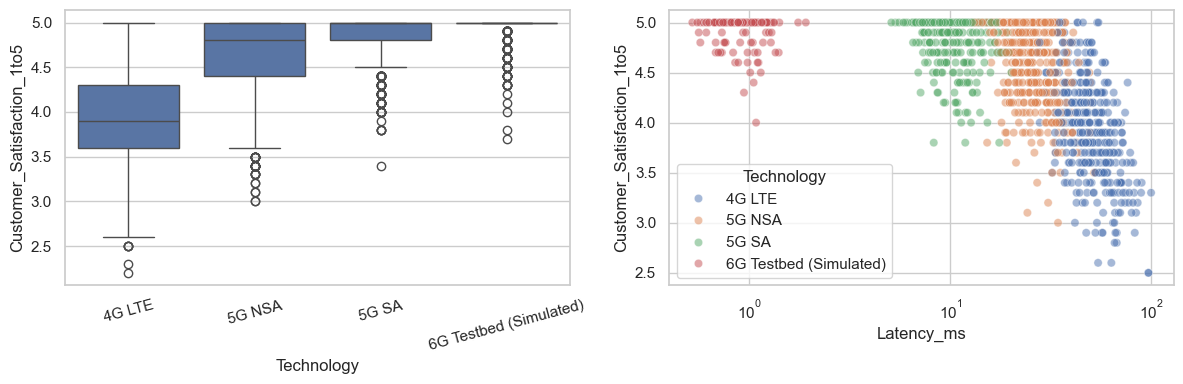

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=df, x="Technology", y="Customer_Satisfaction_1to5", ax=ax[0]); ax[0].tick_params(axis="x", rotation=15)
sns.scatterplot(data=df.sample(1500, random_state=1), x="Latency_ms", y="Customer_Satisfaction_1to5",
                hue="Technology", alpha=0.5, ax=ax[1]); ax[1].set_xscale("log")
plt.tight_layout(); plt.show()

## 7. Trend over time

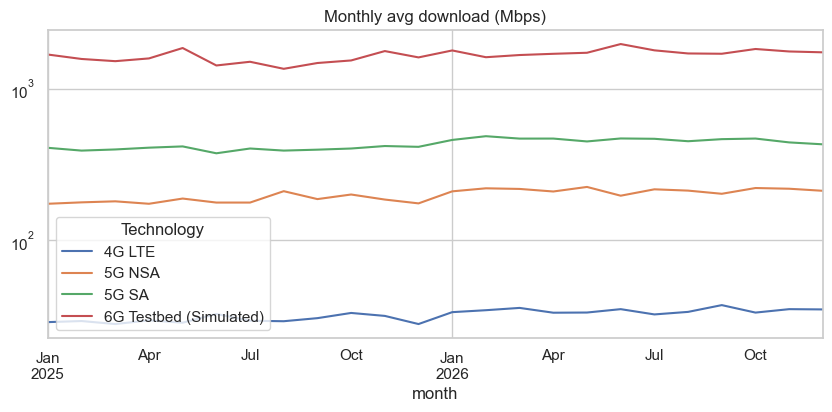

In [17]:
trend = (df.assign(month=df.Date.dt.to_period("M").dt.to_timestamp())
           .groupby(["month","Technology"], observed=True).Download_Mbps.mean().unstack())
trend.plot(figsize=(10,4), title="Monthly avg download (Mbps)"); plt.yscale("log"); plt.show()

## 8. Key findings
Numbers below come from running this notebook on the dataset.
1. 5G SA is roughly 13x faster than 4G, with about 80% lower latency.
2. On 5G SA, Tier-3 cities average about 297 Mbps vs 491 in Metro, a gap of roughly 39%. Tier-2 trails by about 21%.
3. Peak hours (18:00 to 23:00) cut speeds by about 30% on every technology, so congestion is a capacity issue, not a generation issue.
4. Autonomous vehicles (5 ms) are met 0% of the time even on 5G SA, and telemedicine, AR/VR and industrial IoT only about 41 to 47%. Only the simulated 6G meets them all.
5. Energy per GB falls with each generation, while revenue per user and satisfaction rise.

**Recommendation:** prioritize 5G SA in Tier-3 cities and launch mission-critical services first.

**Limitations:** synthetic data, simulated 6G, assumed latency thresholds. Next step: replace the data with Ookla or TRAI data.